In [2]:
!pip install -q kagglehub

import kagglehub

path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print(path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
/kaggle/input/brain-tumor-mri-dataset


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
import random
import time

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from keras import metrics
from keras.layers import Dense, Flatten
from keras.models import Model
from keras.applications.mobilenet_v2 import MobileNetV2

## Preparing the training and testing data

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    "/kaggle/input/brain-tumor-mri-dataset/Training",
    image_size=(224, 224),
    batch_size=64,
    label_mode="int"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/kaggle/input/brain-tumor-mri-dataset/Testing",
    image_size=(224, 224),
    batch_size=64,
    label_mode="int"
)

Found 5600 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.


## Normalize the images

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.map(
    lambda x, y: (tf.cast(x, tf.float32) / 255.0, y),
    num_parallel_calls=AUTOTUNE
)

test_ds = test_ds.map(
    lambda x, y: (tf.cast(x, tf.float32) / 255.0, y),
    num_parallel_calls=AUTOTUNE
)

train_ds = train_ds.prefetch(1)
test_ds = test_ds.prefetch(1)

## Creating the MobileNet_V2 transfer model

In [ ]:
model_temp = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
model_temp.trainable = False
x = model_temp.output
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = Dense(4, activation='softmax')(x)

model_MobileNetV2 = Model(inputs=model_temp.input, outputs=x)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.99)
model_MobileNetV2.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer,
                     metrics=['accuracy'])

model_MobileNetV2.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_3[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Training the MobilNet_V2 transfer model

In [ ]:
t1=time.time()
history_MobileNetV2 = model_MobileNetV2.fit(train_ds, epochs=50, batch_size=64)
t2=time.time()
print()
print('The training of 50 epochs of the Transfer Learning model took',round((t2-t1)/60),'minutes.')

Epoch 1/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 12s 128ms/step - accuracy: 0.8239 - loss: 0.4926
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 101ms/step - accuracy: 0.8777 - loss: 0.3477
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 100ms/step - accuracy: 0.8995 - loss: 0.2880
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 101ms/step - accuracy: 0.9123 - loss: 0.2546
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 100ms/step - accuracy: 0.9202 - loss: 0.2319
Epoch 6/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 100ms/step - accuracy: 0.9273 - loss: 0.2106
Epoch 7/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 101ms/step - accuracy: 0.9309 - loss: 0.1957
Epoch 8/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 101ms/step - accuracy: 0.9382 - loss: 0.1811
Epoch 9/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 100ms/step - accuracy: 0.9427 - loss: 0.1709
Epoch 10/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 100ms/step - accuracy: 0.9459 - loss: 0.1602
Epoch 11/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 102ms/step - accuracy: 0.9511 - loss: 0.1523
Epoch 12/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 100ms/ste

In [ ]:
results =  model_MobileNetV2.evaluate(test_ds, return_dict=True)

print("Test Accuracy:", results['accuracy'])
print("Test Loss:", results['loss'])

25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.9100 - loss: 0.5645
Test Accuracy: 0.9100000262260437
Test Loss: 0.564490556716919


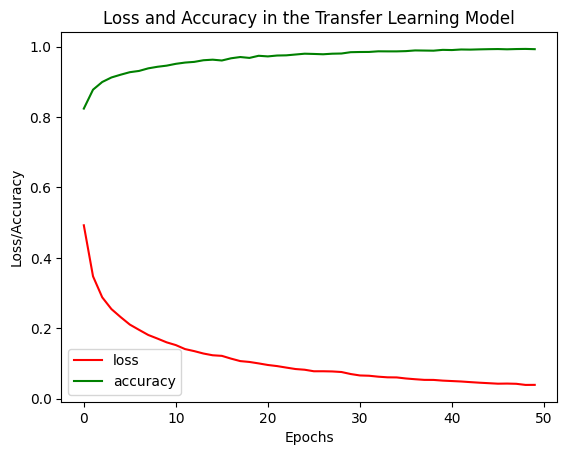

In [ ]:
plt.plot(history_MobileNetV2.history["loss"],c="red")
plt.plot(history_MobileNetV2.history["accuracy"],c="green")
plt.title("Loss and Accuracy in the Transfer Learning Model")
plt.ylabel("Loss/Accuracy")
plt.xlabel("Epochs")
plt.legend(['loss','accuracy'])
plt.show()

In [ ]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model_MobileNetV2.predict(images, verbose=0)

    y_true.extend(labels.numpy().reshape(-1))
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_true, y_pred))

# print("Precision:", precision_score(y_true, y_pred, zero_division=0))

# print("Recall:", recall_score(y_true, y_pred, zero_division=0))

# print("F1-Score:", f1_score(y_true, y_pred, zero_division=0))

print(classification_report(y_true, y_pred, target_names=['glioma', 'meningioma', 'notumor', 'pituitary']))

Accuracy: 0.91
              precision    recall  f1-score   support

      glioma       0.95      0.72      0.82       400
  meningioma       0.80      0.93      0.86       400
     notumor       0.96      1.00      0.98       400
   pituitary       0.96      0.99      0.98       400

    accuracy                           0.91      1600
   macro avg       0.92      0.91      0.91      1600
weighted avg       0.92      0.91      0.91      1600



In [ ]:
model_MobileNetV2.save('tensorflow_model_T01.keras')

## Load Model

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [3]:
model = tf.keras.models.load_model("/tensorflow_model_T01.keras")

print(model.input_shape)
print(model.output_shape)

(None, 224, 224, 3)
(None, 4)


In [8]:
for i, layer in enumerate(model.layers):
    print(i,layer.name, layer.output.shape)

0 input_layer_3 (None, 224, 224, 3)
1 Conv1 (None, 112, 112, 32)
2 bn_Conv1 (None, 112, 112, 32)
3 Conv1_relu (None, 112, 112, 32)
4 expanded_conv_depthwise (None, 112, 112, 32)
5 expanded_conv_depthwise_BN (None, 112, 112, 32)
6 expanded_conv_depthwise_relu (None, 112, 112, 32)
7 expanded_conv_project (None, 112, 112, 16)
8 expanded_conv_project_BN (None, 112, 112, 16)
9 block_1_expand (None, 112, 112, 96)
10 block_1_expand_BN (None, 112, 112, 96)
11 block_1_expand_relu (None, 112, 112, 96)
12 block_1_pad (None, 113, 113, 96)
13 block_1_depthwise (None, 56, 56, 96)
14 block_1_depthwise_BN (None, 56, 56, 96)
15 block_1_depthwise_relu (None, 56, 56, 96)
16 block_1_project (None, 56, 56, 24)
17 block_1_project_BN (None, 56, 56, 24)
18 block_2_expand (None, 56, 56, 144)
19 block_2_expand_BN (None, 56, 56, 144)
20 block_2_expand_relu (None, 56, 56, 144)
21 block_2_depthwise (None, 56, 56, 144)
22 block_2_depthwise_BN (None, 56, 56, 144)
23 block_2_depthwise_relu (None, 56, 56, 144)
24 bloc

In [10]:
model.layers[151]

<Conv2D name=Conv_1, built=True>

In [11]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array, training=False)
        predicted_class = tf.argmax(predictions[0])
        class_score = predictions[:, predicted_class]

    grads = tape.gradient(class_score, conv_outputs)

    # Average gradients across spatial dimensions
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Weight the feature maps by their gradients
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # Normalize between 0 and 1
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + tf.keras.backend.epsilon())

    return heatmap.numpy(), int(predicted_class.numpy())

In [35]:
img_path = "/kaggle/input/brain-tumor-mri-dataset/Testing/pituitary/Te-pi_10.jpg"
img_size = (224, 224)

# Load original image for visualization
original_img = tf.keras.utils.load_img(
    img_path,
    target_size=img_size
)
original_img = tf.keras.utils.img_to_array(original_img).astype("uint8")

# Prepare model input
img_array = tf.keras.utils.img_to_array(
    tf.keras.utils.load_img(img_path, target_size=img_size)
)
img_array = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

heatmap, predicted_class = make_gradcam_heatmap(
    img_array,
    model,
    last_conv_layer_name="out_relu"
)

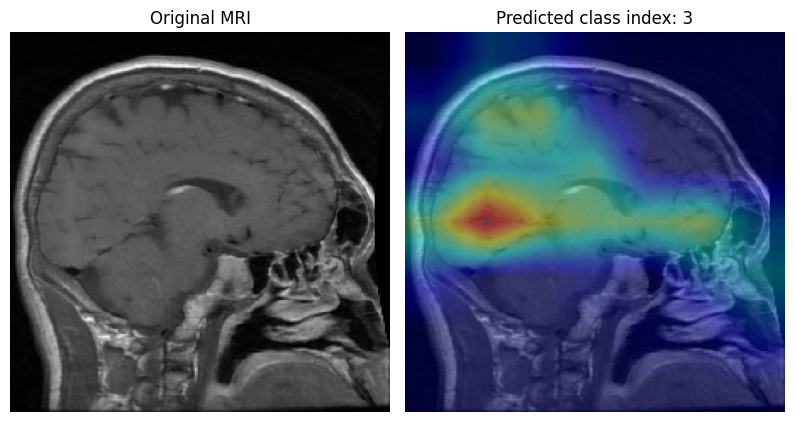

In [36]:
# Resize heatmap to image size
heatmap_resized = cv2.resize(
    heatmap,
    (original_img.shape[1], original_img.shape[0])
)

# Convert heatmap to a color map
heatmap_colored = cv2.applyColorMap(
    np.uint8(255 * heatmap_resized),
    cv2.COLORMAP_JET
)
heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

# Overlay on original image
overlay = np.clip(
    0.6 * original_img + 0.4 * heatmap_colored,
    0,
    255
).astype("uint8")

plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.imshow(original_img)
plt.title("Original MRI")
plt.axis("off")

# plt.subplot(1, 3, 2)
# plt.imshow(heatmap_resized, cmap="jet")
# plt.title("Grad-CAM Heatmap")
# plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(overlay)
plt.title(f"Predicted class index: {predicted_class}")
plt.axis("off")

plt.tight_layout()
plt.show()